In [23]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.distance import add_distance_scores 
from src.budget import add_budget_scores

print("Project root:", PROJECT_ROOT)
print("Imports successful!")

Project root: /Users/stacey/Downloads/Egocentric-Activity-Recommendation-System
Imports successful!


In [24]:
candidates = pd.read_csv(
    PROJECT_ROOT / "data" / "shared_bpr_candidates.csv"
)

activities = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "activity_dataset.csv"
)

In [25]:
activity_features = activities[
    ["gmap_id", "latitude", "longitude", "price"]
].drop_duplicates(subset="gmap_id")

candidates = candidates.merge(
    activity_features,
    on="gmap_id",
    how="left",
    validate="many_to_one"
)


In [26]:
user_location = (40.7580, -73.9855)  # Times Square
radius_miles = 5
max_budget = 2  # Google price level $$

scored = add_distance_scores(
    candidates,
    user_location,
    radius_miles
)

scored = add_budget_scores(
    scored,
    max_budget
)

display(scored[[
    "gmap_id",
    "price",
    "distance_miles",
    "distance_score",
    "budget_score"
]].head(10))

print("Missing prices:", scored["price"].isna().sum())

print("\nBudget scores for missing prices:")
print(
    scored.loc[
        scored["price"].isna(),
        "budget_score"
    ].value_counts(dropna=False)
)

,gmap_id,price,distance_miles,distance_score,budget_score
0,0x89c2f3747f378f7d:0x61caa819e454f065,NaN,9.764754,-0.952951,0.0
1,0x89c2f4e9f911e9d9:0x63082da1140b9e66,$$,8.078725,-0.615745,1.0
2,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,$$,9.799354,-0.959871,1.0
3,0x89c2f3926691fd75:0xae683d2e5147a9a8,$$,8.938753,-0.787751,1.0
4,0x89c28cba56f51c3d:0xe19c58eeca84032f,$$,11.036146,-1.000000,1.0
5,0x89c2f475382671b5:0xba3e30bc6b46ce72,$$,8.153335,-0.630667,1.0
6,0x89c2f48036d65f93:0xc5a253c27b0d884b,$,8.683673,-0.736735,1.0
7,0x89c2f38f07a99cc1:0xa2b82e65b3b2a94b,$$,8.812820,-0.762564,1.0
8,0x89c2f3868be16e11:0x91ed6a50bd941b37,NaN,8.700131,-0.740026,0.0
9,0x89c2f396c9fea93b:0x4ce63bab0b0eaeb0,NaN,9.250727,-0.850145,0.0


Missing prices: 1682

Budget scores for missing prices:
budget_score
0.0    1682
Name: count, dtype: int64


In [27]:
from itertools import product

distance_weights = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
budget_weights = [0, 0.05, 0.1, 0.15, 0.2, 0.3]

experiment_results = {}

for wd, wb in product(distance_weights, budget_weights):

    df = scored.copy()

    df["final_score"] = (
        df["bpr_normalized"]
        + wd * df["distance_score"]
        + wb * df["budget_score"]
    )

    top10 = (
        df.sort_values(
            ["user_id", "final_score", "bpr_rank"],
            ascending=[True, False, True]
        )
        .groupby("user_id")
        .head(10)
        .copy()
    )

    experiment_results[(wd, wb)] = top10

print("Total experiments:", len(experiment_results))

display(experiment_results[(0.3, 0.1)].head(10))

Total experiments: 36


,user_id,gmap_id,bpr_rank,bpr_score,bpr_normalized,latitude,longitude,price,distance_miles,distance_score,budget_score,final_score
1,100388958952721979686,0x89c2f4e9f911e9d9:0x63082da1140b9e66,2,2.832877,0.937595,40.831750,-73.865853,$$,8.078725,-0.615745,1.0,0.852872
3,100388958952721979686,0x89c2f3926691fd75:0xae683d2e5147a9a8,4,2.800888,0.857444,40.873787,-73.909044,$$,8.938753,-0.787751,1.0,0.721118
0,100388958952721979686,0x89c2f3747f378f7d:0x61caa819e454f065,1,2.857783,1.000000,40.875824,-73.882335,NaN,9.764754,-0.952951,0.0,0.714115
11,100388958952721979686,0x89c2f4332bd656cf:0x4d44b89dceef33fe,12,2.719425,0.653331,40.825094,-73.921582,$,5.715827,-0.143165,1.0,0.710381
2,100388958952721979686,0x89c2f3a32b7ceaeb:0x3c3cecb4c22cf890,3,2.815485,0.894019,40.884421,-73.900340,$$,9.799354,-0.959871,1.0,0.706058
5,100388958952721979686,0x89c2f475382671b5:0xba3e30bc6b46ce72,6,2.753277,0.738152,40.862052,-73.911813,$$,8.153335,-0.630667,1.0,0.648951
15,100388958952721979686,0x89c2f4532b916b3b:0x3e650ed150052e93,16,2.707852,0.624333,40.822062,-73.897490,$,6.391028,-0.278206,1.0,0.640872
4,100388958952721979686,0x89c28cba56f51c3d:0xe19c58eeca84032f,5,2.792721,0.836982,40.864406,-73.828345,$$,11.036146,-1.000000,1.0,0.636982
6,100388958952721979686,0x89c2f48036d65f93:0xc5a253c27b0d884b,7,2.751440,0.733548,40.858858,-73.886448,$,8.683673,-0.736735,1.0,0.612527
31,100388958952721979686,0x89c2f5d198cb3613:0xe5b419e5b08f42c9,32,2.656347,0.495284,40.817430,-73.922245,$,5.274740,-0.054948,1.0,0.578800


In [28]:
# Original BPR Top-10 for comparison
baseline_top10 = experiment_results[(0, 0)]

baseline_ids = {
    user_id: set(group["gmap_id"])
    for user_id, group in baseline_top10.groupby("user_id")
}

price_levels = {
    "$": 1,
    "$$": 2,
    "$$$": 3,
    "$$$$": 4
}

results = []

for (wd, wb), top10 in experiment_results.items():

    user_results = []

    for user_id, group in top10.groupby("user_id"):

        within_radius = (
            group["distance_miles"] <= radius_miles
        )

        activity_prices = group["price"].map(price_levels)
        known_prices = activity_prices.notna()

        within_budget = (
            activity_prices <= max_budget
        )

        overlap = (
            len(set(group["gmap_id"]) & baseline_ids[user_id])
            / len(baseline_ids[user_id])
        )

        user_results.append({
            "within_radius": within_radius.mean(),
            "within_budget": (
                within_budget[known_prices].mean()
                if known_prices.any()
                else np.nan
            ),
            "joint_compatibility": (
                (within_radius & within_budget).mean()
            ),
            "bpr_overlap": overlap,
            "price_coverage": known_prices.mean()
        })

    user_df = pd.DataFrame(user_results)

    results.append({
        "distance_weight": wd,
        "budget_weight": wb,
        "within_radius": user_df["within_radius"].mean(),
        "within_budget": user_df["within_budget"].mean(),
        "joint_compatibility": user_df["joint_compatibility"].mean(),
        "bpr_overlap": user_df["bpr_overlap"].mean(),
        "price_coverage": user_df["price_coverage"].mean()
    })

results_df = pd.DataFrame(results)

display(results_df.round(3))

,distance_weight,budget_weight,within_radius,within_budget,joint_compatibility,bpr_overlap,price_coverage
0,0.0,0.00,0.320,0.938,0.218,1.000,0.752
1,0.0,0.05,0.324,0.955,0.240,0.934,0.804
2,0.0,0.10,0.324,0.971,0.258,0.876,0.848
3,0.0,0.15,0.328,0.982,0.276,0.834,0.880
4,0.0,0.20,0.330,0.995,0.294,0.796,0.906
5,0.0,0.30,0.332,0.998,0.310,0.760,0.940
6,0.1,0.00,0.356,0.933,0.240,0.946,0.768
7,0.1,0.05,0.358,0.956,0.264,0.900,0.808
8,0.1,0.10,0.358,0.975,0.282,0.850,0.848
9,0.1,0.15,0.358,0.985,0.302,0.800,0.892


In [29]:
models = {
    "BPR Only": (0.0, 0.0),
    "Distance Only": (0.3, 0.0),
    "Budget Only": (0.0, 0.1),
    "Distance + Budget": (0.3, 0.1)
}

comparison = []

for model_name, (wd, wb) in models.items():

    row = results_df[
        np.isclose(results_df["distance_weight"], wd)
        & np.isclose(results_df["budget_weight"], wb)
    ].iloc[0].copy()

    row["model"] = model_name
    comparison.append(row)

comparison_df = pd.DataFrame(comparison)

comparison_df = comparison_df[
    [
        "model",
        "within_radius",
        "within_budget",
        "joint_compatibility",
        "bpr_overlap",
        "price_coverage"
    ]
]

display(comparison_df.round(3))

,model,within_radius,within_budget,joint_compatibility,bpr_overlap,price_coverage
0,BPR Only,0.320,0.938,0.218,1.000,0.752
18,Distance Only,0.420,0.932,0.280,0.840,0.786
2,Budget Only,0.324,0.971,0.258,0.876,0.848
20,Distance + Budget,0.424,0.973,0.336,0.776,0.866


In [30]:
baseline = comparison_df[
    comparison_df["model"] == "BPR Only"
].iloc[0]

improvements = comparison_df.copy()

metrics = [
    "within_radius",
    "within_budget",
    "joint_compatibility",
    "bpr_overlap"
]

for metric in metrics:
    improvements[metric] = (
        comparison_df[metric] - baseline[metric]
    ) * 100

display(improvements.round(2))

,model,within_radius,within_budget,joint_compatibility,bpr_overlap,price_coverage
0,BPR Only,0.0,0.00,0.0,0.0,0.75
18,Distance Only,10.0,-0.61,6.2,-16.0,0.79
2,Budget Only,0.4,3.34,4.0,-12.4,0.85
20,Distance + Budget,10.4,3.54,11.8,-22.4,0.87


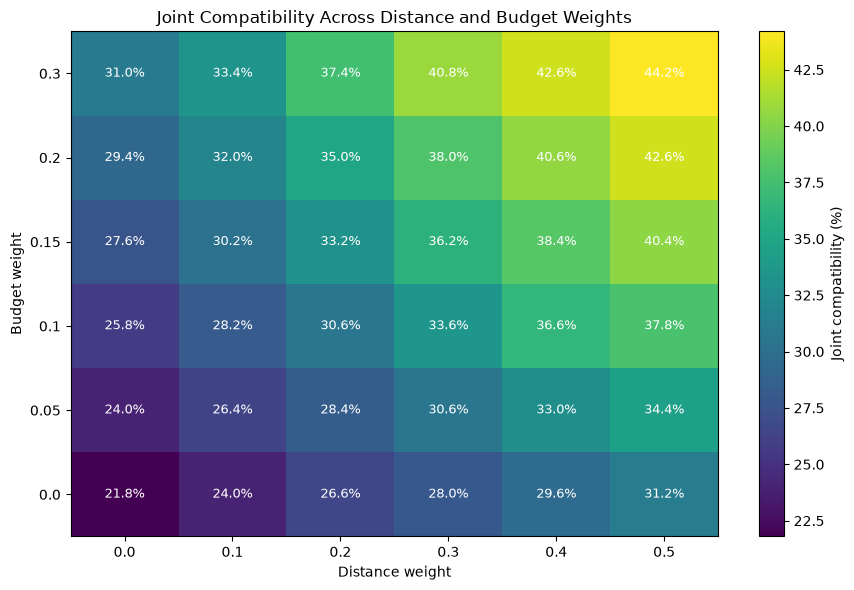

In [31]:
import matplotlib.pyplot as plt

pivot = results_df.pivot(
    index="budget_weight",
    columns="distance_weight",
    values="joint_compatibility"
)

fig, ax = plt.subplots(figsize=(9, 6))

heatmap = ax.imshow(
    pivot.values * 100,
    aspect="auto",
    origin="lower",
    cmap="viridis"
)

ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)

ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)

ax.set_xlabel("Distance weight")
ax.set_ylabel("Budget weight")
ax.set_title("Joint Compatibility Across Distance and Budget Weights")

for i in range(len(pivot.index)):
    for j in range(len(pivot.columns)):
        ax.text(
            j, i,
            f"{pivot.iloc[i, j] * 100:.1f}%",
            ha="center",
            va="center",
            color="white",
            fontsize=9
        )

fig.colorbar(heatmap, ax=ax, label="Joint compatibility (%)")

plt.tight_layout()
plt.show()

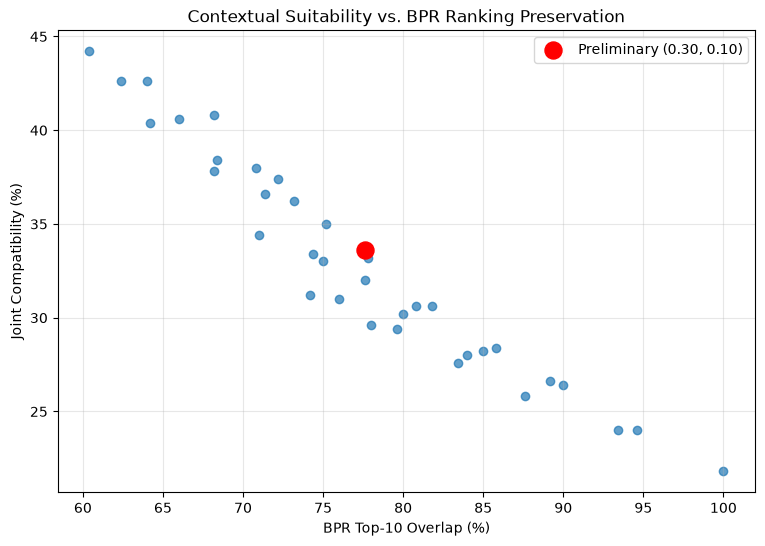

In [32]:
fig, ax = plt.subplots(figsize=(9, 6))

ax.scatter(
    results_df["bpr_overlap"] * 100,
    results_df["joint_compatibility"] * 100,
    alpha=0.7
)

# Highlight your preliminary weights
preliminary = results_df[
    np.isclose(results_df["distance_weight"], 0.3)
    & np.isclose(results_df["budget_weight"], 0.1)
].iloc[0]

ax.scatter(
    preliminary["bpr_overlap"] * 100,
    preliminary["joint_compatibility"] * 100,
    s=150,
    color="red",
    label="Preliminary (0.30, 0.10)",
    zorder=5
)

ax.set_xlabel("BPR Top-10 Overlap (%)")
ax.set_ylabel("Joint Compatibility (%)")
ax.set_title("Contextual Suitability vs. BPR Ranking Preservation")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [33]:
promising = results_df[
    results_df["bpr_overlap"] >= 0.75
].copy()

promising = promising.sort_values(
    "joint_compatibility",
    ascending=False
)

display(
    promising[
        [
            "distance_weight",
            "budget_weight",
            "joint_compatibility",
            "bpr_overlap",
            "within_radius",
            "within_budget",
            "price_coverage"
        ]
    ].head(10).round(3)
)

,distance_weight,budget_weight,joint_compatibility,bpr_overlap,within_radius,within_budget,price_coverage
16,0.2,0.20,0.350,0.752,0.392,0.994,0.916
20,0.3,0.10,0.336,0.776,0.424,0.973,0.866
15,0.2,0.15,0.332,0.778,0.390,0.986,0.896
25,0.4,0.05,0.330,0.750,0.446,0.957,0.840
10,0.1,0.20,0.320,0.776,0.358,0.996,0.912
5,0.0,0.30,0.310,0.760,0.332,0.998,0.940
14,0.2,0.10,0.306,0.818,0.390,0.975,0.854
19,0.3,0.05,0.306,0.808,0.422,0.957,0.824
9,0.1,0.15,0.302,0.800,0.358,0.985,0.892
24,0.4,0.00,0.296,0.780,0.446,0.933,0.792


In [34]:
candidate_weights = [
    (0.0, 0.0),
    (0.2, 0.1),
    (0.2, 0.2),
    (0.3, 0.1)
]

selected = results_df[
    results_df.apply(
        lambda row: any(
            np.isclose(row["distance_weight"], wd)
            and np.isclose(row["budget_weight"], wb)
            for wd, wb in candidate_weights
        ),
        axis=1
    )
].copy()

selected["model"] = selected.apply(
    lambda row: (
        "BPR Only"
        if np.isclose(row["distance_weight"], 0)
        and np.isclose(row["budget_weight"], 0)
        else f"Distance {row['distance_weight']:.1f}, "
             f"Budget {row['budget_weight']:.1f}"
    ),
    axis=1
)

display(
    selected[
        [
            "model",
            "within_radius",
            "within_budget",
            "joint_compatibility",
            "bpr_overlap",
            "price_coverage"
        ]
    ].round(3)
)

,model,within_radius,within_budget,joint_compatibility,bpr_overlap,price_coverage
0,BPR Only,0.320,0.938,0.218,1.000,0.752
14,"Distance 0.2, Budget 0.1",0.390,0.975,0.306,0.818,0.854
16,"Distance 0.2, Budget 0.2",0.392,0.994,0.350,0.752,0.916
20,"Distance 0.3, Budget 0.1",0.424,0.973,0.336,0.776,0.866


In [35]:
test = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "test20.csv"
)

print("Shape:", test.shape)

print("\nColumns:")
print(test.columns.tolist())

print("\nUnique users:", test["user_id"].nunique()
      if "user_id" in test.columns else "Unknown")

display(test.head())

Shape: (1676534, 4)

Columns:
['user_id', 'gmap_id', 'rating', 'time']

Unique users: 552621


,user_id,gmap_id,rating,time
0,100000012795753291799,0x89c25a4c43c5a19f:0x3f6401582b49c95c,4,1617057156812
1,100000036464530353686,0x89c2f5b9faaed00f:0x8b1a77bb24200925,5,1557705305074
2,100000036464530353686,0x89c258ff48e75613:0x1de767bc6d9ae0c,5,1557705390025
3,100000036464530353686,0x89c2f662a75ebad5:0x54bfc08ac601aa8d,5,1561338245436
4,100000036464530353686,0x89c28c633b025067:0x8dd7fd3725821408,5,1561338251913


In [36]:
validation_files = [
    "validation20.csv",
    "validation_positive_1000_users.csv",
    "validation_sample_1000_users.csv"
]

for filename in validation_files:
    path = PROJECT_ROOT / "data" / "processed" / filename

    df = pd.read_csv(path)

    print(f"\n{filename}")
    print("Shape:", df.shape)
    print("Columns:", df.columns.tolist())

    if "user_id" in df.columns:
        print("Unique users:", df["user_id"].nunique())


validation20.csv
Shape: (1680489, 4)
Columns: ['user_id', 'gmap_id', 'rating', 'time']
Unique users: 553090

validation_positive_1000_users.csv
Shape: (1000, 1)
Columns: ['user_id']
Unique users: 1000

validation_sample_1000_users.csv
Shape: (1000, 1)
Columns: ['user_id']
Unique users: 1000


In [37]:
# Load validation interactions
validation = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "validation20.csv",
    dtype={"user_id": str, "gmap_id": str}
)

# Ensure consistent ID types
candidates["user_id"] = candidates["user_id"].astype(str)
candidates["gmap_id"] = candidates["gmap_id"].astype(str)

# Get experiment users
experiment_users = set(candidates["user_id"])

# Filter validation to our 50 users
validation_subset = validation[
    validation["user_id"].isin(experiment_users)
].copy()

print("Experiment users:", len(experiment_users))

print(
    "Users found in validation:",
    validation_subset["user_id"].nunique()
)

print(
    "Validation interactions:",
    len(validation_subset)
)

# Match validation interactions to BPR candidate pairs
candidate_pairs = pd.MultiIndex.from_frame(
    candidates[["user_id", "gmap_id"]]
)

validation_pairs = pd.MultiIndex.from_frame(
    validation_subset[["user_id", "gmap_id"]]
)

matches = validation_pairs.isin(candidate_pairs)

print(
    "Validation interactions found in BPR candidates:",
    matches.sum()
)

print(
    "Users with at least one matching candidate:",
    validation_subset.loc[matches, "user_id"].nunique()
)

Experiment users: 50
Users found in validation: 50
Validation interactions: 99
Validation interactions found in BPR candidates: 19
Users with at least one matching candidate: 14


In [38]:
from src.eval_metrics import calculate_metrics

# Relevant validation activities for each user
relevant_items = (
    validation_subset.groupby("user_id")["gmap_id"]
    .apply(set)
    .to_dict()
)

# Models to compare
selected_models = {
    "BPR Only": (0.0, 0.0),
    "Distance 0.2, Budget 0.1": (0.2, 0.1),
    "Distance 0.2, Budget 0.2": (0.2, 0.2),
    "Distance 0.3, Budget 0.1": (0.3, 0.1)
}

evaluation_results = []

for model_name, weights in selected_models.items():

    top10 = experiment_results[weights]
    user_metrics = []

    for user_id, group in top10.groupby("user_id"):

        relevant = relevant_items.get(str(user_id), set())

        if not relevant:
            continue

        # Sort by the model's final ranking
        group = group.sort_values(
            ["final_score", "bpr_rank"],
            ascending=[False, True]
        )

        recommended = group["gmap_id"].astype(str).tolist()

        # Reuse your existing evaluation functions
        metrics = calculate_metrics(
            recommended,
            relevant,
            k=10
        )

        user_metrics.append(metrics)

    metrics_df = pd.DataFrame(user_metrics)

    evaluation_results.append({
        "model": model_name,
        "Recall@10": metrics_df["Recall@10"].mean(),
        "HitRate@10": metrics_df["HitRate@10"].mean(),
        "NDCG@10": metrics_df["NDCG@10"].mean()
    })

relevance_df = pd.DataFrame(evaluation_results)

display(relevance_df.round(4))

,model,Recall@10,HitRate@10,NDCG@10
0,BPR Only,0.0267,0.06,0.0165
1,"Distance 0.2, Budget 0.1",0.0267,0.06,0.0173
2,"Distance 0.2, Budget 0.2",0.0267,0.06,0.0173
3,"Distance 0.3, Budget 0.1",0.0267,0.06,0.0165


In [39]:
all_relevance_results = []

for (wd, wb), top10 in experiment_results.items():

    user_metrics = []

    for user_id, group in top10.groupby("user_id"):

        relevant = relevant_items.get(str(user_id), set())

        if not relevant:
            continue

        group = group.sort_values(
            ["final_score", "bpr_rank"],
            ascending=[False, True]
        )

        recommended = group["gmap_id"].astype(str).tolist()

        metrics = calculate_metrics(
            recommended,
            relevant,
            k=10
        )

        user_metrics.append(metrics)

    metrics_df = pd.DataFrame(user_metrics)

    all_relevance_results.append({
        "distance_weight": wd,
        "budget_weight": wb,
        "Recall@10": metrics_df["Recall@10"].mean(),
        "HitRate@10": metrics_df["HitRate@10"].mean(),
        "NDCG@10": metrics_df["NDCG@10"].mean()
    })

all_relevance_df = pd.DataFrame(all_relevance_results)

# Combine relevance and contextual evaluation
full_results = results_df.merge(
    all_relevance_df,
    on=["distance_weight", "budget_weight"]
)

display(
    full_results.sort_values(
        ["NDCG@10", "joint_compatibility"],
        ascending=False
    ).head(10).round(4)
)

,distance_weight,budget_weight,within_radius,within_budget,joint_compatibility,bpr_overlap,price_coverage,Recall@10,HitRate@10,NDCG@10
17,0.2,0.30,0.396,1.0000,0.374,0.722,0.950,0.0267,0.06,0.0173
16,0.2,0.20,0.392,0.9936,0.350,0.752,0.916,0.0267,0.06,0.0173
11,0.1,0.30,0.352,0.9978,0.334,0.744,0.946,0.0267,0.06,0.0173
15,0.2,0.15,0.390,0.9856,0.332,0.778,0.896,0.0267,0.06,0.0173
10,0.1,0.20,0.358,0.9958,0.320,0.776,0.912,0.0267,0.06,0.0173
5,0.0,0.30,0.332,0.9978,0.310,0.760,0.940,0.0267,0.06,0.0173
14,0.2,0.10,0.390,0.9753,0.306,0.818,0.854,0.0267,0.06,0.0173
9,0.1,0.15,0.358,0.9853,0.302,0.800,0.892,0.0267,0.06,0.0173
4,0.0,0.20,0.330,0.9951,0.294,0.796,0.906,0.0267,0.06,0.0173
13,0.2,0.05,0.390,0.9567,0.284,0.858,0.816,0.0267,0.06,0.0173


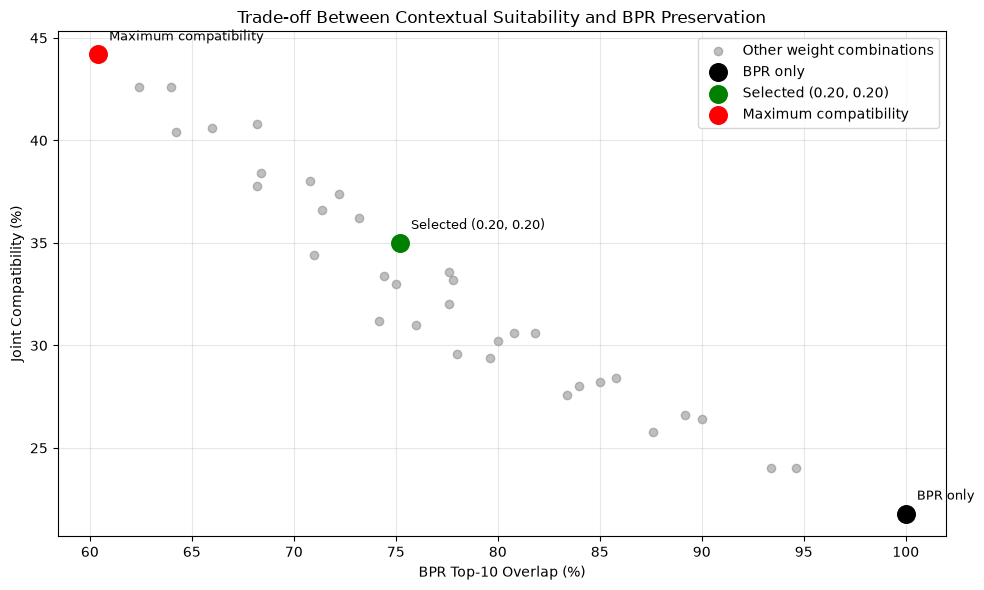

In [40]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    full_results["bpr_overlap"] * 100,
    full_results["joint_compatibility"] * 100,
    alpha=0.5,
    color="gray",
    label="Other weight combinations"
)

highlight = [
    (0.0, 0.0, "BPR only", "black"),
    (0.2, 0.2, "Selected (0.20, 0.20)", "green"),
    (0.5, 0.3, "Maximum compatibility", "red")
]

for wd, wb, label, color in highlight:
    row = full_results[
        np.isclose(full_results["distance_weight"], wd)
        & np.isclose(full_results["budget_weight"], wb)
    ].iloc[0]

    ax.scatter(
        row["bpr_overlap"] * 100,
        row["joint_compatibility"] * 100,
        s=160,
        color=color,
        label=label,
        zorder=5
    )

    ax.annotate(
        label,
        (
            row["bpr_overlap"] * 100,
            row["joint_compatibility"] * 100
        ),
        xytext=(8, 10),
        textcoords="offset points",
        fontsize=9
    )

ax.set_xlabel("BPR Top-10 Overlap (%)")
ax.set_ylabel("Joint Compatibility (%)")
ax.set_title("Trade-off Between Contextual Suitability and BPR Preservation")
ax.grid(alpha=0.3)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

In [41]:
models = {
    "BPR only": (0.0, 0.0),
    "Distance only": (0.3, 0.0),
    "Budget only": (0.0, 0.1),
    "Selected": (0.2, 0.2),
    "Maximum compatibility": (0.5, 0.3)
}

rows = []

for name, (wd, wb) in models.items():
    match = full_results[
        np.isclose(full_results["distance_weight"], wd)
        & np.isclose(full_results["budget_weight"], wb)
    ].iloc[0]

    rows.append({
        "Model": name,
        "Distance weight": wd,
        "Budget weight": wb,
        "Joint fit": match["joint_compatibility"],
        "BPR overlap": match["bpr_overlap"],
        "Recall@10": match["Recall@10"],
        "HitRate@10": match["HitRate@10"],
        "NDCG@10": match["NDCG@10"]
    })

report = pd.DataFrame(rows)

styled = (
    report.style
    .format({
        "Distance weight": "{:.2f}",
        "Budget weight": "{:.2f}",
        "Joint fit": "{:.1%}",
        "BPR overlap": "{:.1%}",
        "HitRate@10": "{:.4f}",
        "Recall@10": "{:.4f}",
        "NDCG@10": "{:.4f}"
    })
    .hide(axis="index")
    .apply(
        lambda row: (
            ["background-color: #dcefe4; color: #173b29; font-weight: bold"]
            * len(row)
            if row["Model"] == "Selected"
            else [""] * len(row)
        ),
        axis=1
    )
    .set_caption(
        "Distance and Budget Weight Comparison (50 Validation Users)"
    )
)

display(styled)

Model,Distance weight,Budget weight,Joint fit,BPR overlap,Recall@10,HitRate@10,NDCG@10
BPR only,0.00,0.00,21.8%,100.0%,0.0267,0.0600,0.0165
Distance only,0.30,0.00,28.0%,84.0%,0.0267,0.0600,0.0165
Budget only,0.00,0.10,25.8%,87.6%,0.0267,0.0600,0.0173
Selected,0.20,0.20,35.0%,75.2%,0.0267,0.0600,0.0173
Maximum compatibility,0.50,0.30,44.2%,60.4%,0.0267,0.0600,0.0165
